# Re-exports from Jamaica

For many captives, landing in Jamaica was not the end of the journey. Kingston was a hub of
the slave trade within the Americas: people brought from Africa were sold again and shipped
on to Spanish America, Saint-Domingue, Cuba and mainland North America. The Intra-American
database (Borucki, O'Malley and colleagues) records over 11,500 such voyages between ports in
the Americas. This notebook follows those that left Jamaica:

- where the people on board were taken;
- when;
- how the re-exports compare with the transatlantic arrivals;
- which Jamaican ports they left from;
- the few journeys that can be traced from the African coast through Jamaica and onward.

A re-export here means an Intra-American voyage whose principal place of embarkation is in
Jamaica and whose principal place of disembarkation is outside Jamaica. Voyages between two
Jamaican ports, the two recorded as going to Africa, and those with no known destination are
counted separately.

**About the numbers.** Numbers are the database's imputed figures unless marked as recorded.
The Intra-American database imputes a number of captives for every voyage, including those
whose records give none. Recorded numbers exist for about half the voyages from Jamaica.
Both count only voyages known to the database, so they are lower bounds.

Needs the full data: `uv run voyages fetch && uv run voyages build`.

In [1]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import pandas as pd

import voyages
from voyages import Voyages

v = Voyages()
JAMAICA = 35100  # region code
from_jamaica = v.intraamerican.embarked_from("Jamaica")

## All voyages leaving Jamaica with captives

In [2]:
everything = from_jamaica.summary()
everything

,dataset,voyages,embarked,voyages_with_embarked,disembarked,voyages_with_disembarked,first_year,last_year,drawable
0,intraamerican,3048,133115,3048,127696,3048,1652,1812,2868


Where those voyages went, grouped as this notebook uses them. The regions are the
database's. Spanish mainland ports are mostly Cartagena, Portobelo and the Venezuelan coast;
"Spanish Americas" means the record names Spanish America but no region. Santo Domingo
("Hispaniola") and Puerto Rico are grouped with the other Spanish islands, and Cuba is kept
apart because its trade had its own timing.

In [3]:
GROUPS = {
    "Spanish mainland": ["Spanish Circum-Caribbean", "Spanish Americas", "Rio de la Plata"],
    "Cuba": ["Cuba"],
    "Other Spanish islands": ["Hispaniola", "Puerto Rico", "Other Spanish Caribbean"],
    "Saint-Domingue": ["Saint-Domingue"],
    "Mainland North America": None,  # every region in that broad region
    "Other Caribbean": None,  # the rest of the Caribbean outside Jamaica
}


def destination(row) -> str:
    region, broad = row.disembarkation_region_name, row.disembarkation_broad_region_name
    if pd.isna(region):
        return "Not known"
    if row.disembarkation_region == JAMAICA:
        return "Within Jamaica"
    if broad == "Africa":
        return "Africa"
    for group, regions in GROUPS.items():
        if regions and region in regions:
            return group
    if broad == "Mainland North America":
        return "Mainland North America"
    return "Other Caribbean"


ORDER = [*GROUPS, "Within Jamaica", "Africa", "Not known"]
rows = from_jamaica.to_pandas(
    [
        "voyage_id",
        "year_arrived_imputed",
        "embarked_imputed",
        "disembarked_imputed",
        "disembarkation_region",
        "disembarkation_region_name",
        "disembarkation_broad_region_name",
    ]
)  # fmt: skip
rows["destination"] = pd.Categorical(rows.apply(destination, axis=1), ORDER, ordered=True)
rows["decade"] = rows.year_arrived_imputed // 10 * 10

by_destination = (
    rows.groupby("destination", observed=False)
    .agg(
        voyages=("voyage_id", "size"),
        embarked=("embarked_imputed", "sum"),
        disembarked=("disembarked_imputed", "sum"),
    )
    .assign(share=lambda d: (d.disembarked / d.disembarked.sum() * 100).round(1))
)
by_destination

,voyages,embarked,disembarked,share
destination,,,,
Spanish mainland,503,62017,60323,47.2
Cuba,825,31739,30415,23.8
Other Spanish islands,95,2640,2558,2.0
Saint-Domingue,322,10592,10176,8.0
Mainland North America,821,13993,12927,10.1
Other Caribbean,368,9950,9568,7.5
Within Jamaica,24,1476,1040,0.8
Africa,2,29,28,0.0
Not known,88,679,661,0.5


The same voyages by region of disembarkation.

In [4]:
by_region = from_jamaica.by(
    "disembarkation_broad_region_name", "disembarkation_region_name",
    measures=["voyages", "disembarked"],
).sort_values("disembarked", ascending=False)  # fmt: skip
by_region

,disembarkation_broad_region_name,disembarkation_region_name,voyages,disembarked
33,Spanish Mainland America,Spanish Circum-Caribbean,410,50613
3,Caribbean,Cuba,825,30415
14,Caribbean,Saint-Domingue,322,10176
31,Other,Spanish Americas,92,9691
20,Mainland North America,Gulf coast,66,3737
29,Mainland North America,South Carolina,226,3638
5,Caribbean,Dutch Caribbean,115,3016
1,Caribbean,Bahamas,56,1875
24,Mainland North America,New York,224,1670
6,Caribbean,Hispaniola,70,1553


From here on, "re-exports" leaves out the voyages within Jamaica, to Africa, and to unknown
destinations.

In [5]:
reexports = rows[rows.destination.isin(list(GROUPS))]
totals = reexports[["embarked_imputed", "disembarked_imputed"]].sum()
re_summary = pd.Series(
    {
        "voyages": len(reexports),
        "embarked": int(totals.embarked_imputed),
        "disembarked": int(totals.disembarked_imputed),
        "first_year": int(reexports.year_arrived_imputed.min()),
        "last_year": int(reexports.year_arrived_imputed.max()),
    }
)
re_summary

voyages          2934
embarked       130931
disembarked    125967
first_year       1652
last_year        1812
dtype: int64

## Over time

People embarked in Jamaica for other colonies, by decade and destination.

In [6]:
by_decade = (
    reexports.pivot_table(
        index="decade",
        columns="destination",
        values="embarked_imputed",
        aggfunc="sum",
        observed=False,
    )  # fmt: skip
    .fillna(0)
    .astype(int)[list(GROUPS)]
)
by_decade["total"] = by_decade.sum(axis=1)
by_decade

destination,Spanish mainland,Cuba,Other Spanish islands,Saint-Domingue,Mainland North America,Other Caribbean,total
decade,,,,,,,
1650,0,0,0,0,44,0,44
1660,817,0,0,0,0,0,817
1680,1991,100,0,0,105,0,2196
1690,604,0,0,0,0,0,604
1700,823,120,0,0,119,0,1062
1710,4711,1150,0,0,943,8,6812
1720,13278,2166,0,0,792,17,16253
1730,20440,3736,282,0,1262,5,25725
1740,10123,897,0,0,387,1437,12844


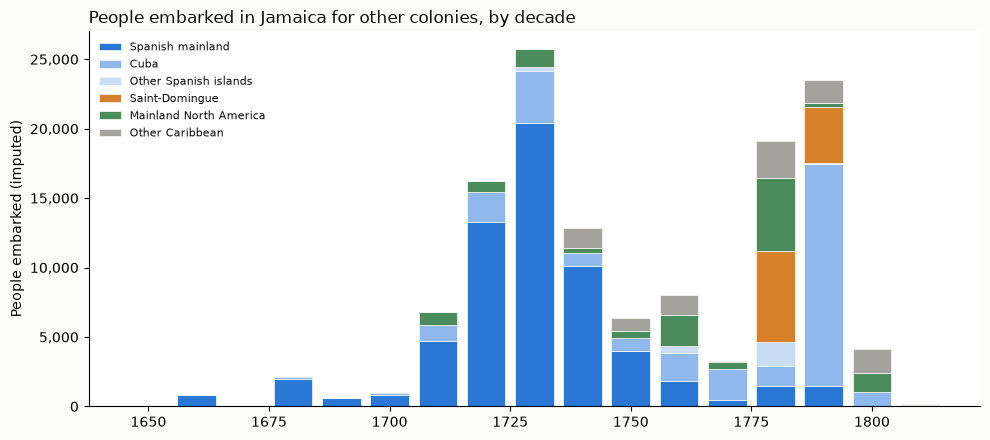

In [7]:
SURFACE, INK, MUTED, LAND, SEA = "#fcfcfb", "#0b0b0b", "#52514e", "#ecebe6", "#fcfcfb"
HIGHLIGHT, CONTEXT = "#2a78d6", "#a3a29c"
COLOURS = {
    "Spanish mainland": "#2a78d6",
    "Cuba": "#8fb8ec",
    "Other Spanish islands": "#c9ddf6",
    "Saint-Domingue": "#d6802a",
    "Mainland North America": "#4a8c5c",
    "Other Caribbean": "#a3a29c",
}
plt.rcParams.update({"figure.facecolor": SURFACE, "text.color": INK, "font.size": 10})

fig, ax = plt.subplots(figsize=(10, 4.5))
bottom = pd.Series(0, index=by_decade.index)
for group in GROUPS:
    ax.bar(
        by_decade.index, by_decade[group], width=8, bottom=bottom, color=COLOURS[group],
        label=group, edgecolor=SURFACE, linewidth=0.5,
    )  # fmt: skip
    bottom += by_decade[group]
ax.set_title("People embarked in Jamaica for other colonies, by decade", loc="left")
ax.set_ylabel("People embarked (imputed)")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig("figures/03_reexports_by_decade.png", dpi=150)

Two peaks stand out:

- **1710s–1740s.** Most re-exports went to the Spanish mainland, chiefly Portobelo and
  Cartagena. These are the years when Britain's South Sea Company held the asiento, the
  Spanish contract to supply captives to Spanish America (from 1713 until war with Spain in
  1739), and Jamaica was a supply point.
- **1780s–1790s.** In the 1780s, mainly Saint-Domingue and mainland North America. In the
  1790s, mainly Cuba, after Spain opened its colonies to foreign traders in captives in 1789.

The trade falls away in the 1800s. Britain's Foreign Slave Trade Act of 1806 barred British
subjects from supplying foreign colonies, and the 1807 Act ended the British slave trade.

## Compared with arrivals from Africa

People embarked in Jamaica for other colonies, as a share of people landed in Jamaica from
Africa in the same decade. The two databases are compiled separately and neither is complete,
so read the share as a rough indication, not a rate. In decades with very few voyages (the
1650s has one of each) the share means little.

Over 1650–1809 as a whole, the people re-exported come to about one in seven of those landed
from Africa. The Intra-American project's own estimate, for the Americas as a whole, is that
about a quarter of arriving Africans were soon shipped on again. Voyages missing from the
Intra-American data would close some of that gap.

In [8]:
arrivals = (
    v.transatlantic.disembarked_in("Jamaica")
    .by_decade("disembarked")
    .dropna(subset=["decade"])
    .set_index("decade")
    .disembarked
)
compared = pd.DataFrame(
    {"landed_from_africa": arrivals, "reexported": by_decade.total}
).fillna(0).astype(int).loc[1650:1809]  # fmt: skip
compared["share"] = (compared.reexported / compared.landed_from_africa * 100).round(1)
overall = compared.sum()
overall_share = round(overall.reexported / overall.landed_from_africa * 100, 1)
compared

,landed_from_africa,reexported,share
decade,,,
1650,85,44,51.8
1660,5530,817,14.8
1670,8562,0,0.0
1680,27244,2196,8.1
1690,17240,604,3.5
1700,49106,1062,2.2
1710,44712,6812,15.2
1720,60898,16253,26.7
1730,68590,25725,37.5


In [9]:
overall_share

np.float64(14.1)

## Ports in Jamaica

Where re-exported captives were put on board. Many records name only "Jamaica"; of the
named ports, Kingston dominates.

In [10]:
ports = (
    from_jamaica.where(
        f"disembarkation_region IS NOT NULL AND disembarkation_region <> {JAMAICA}"
        " AND disembarkation_broad_region_name <> 'Africa'"
    )
    .by("embarkation_place_name", "embarkation_precision", measures=["voyages", "embarked"])
    .sort_values("embarked", ascending=False)
)
ports

,embarkation_place_name,embarkation_precision,voyages,embarked
2,"Jamaica, port unspecified",representative,1401,76474
3,Kingston,place,1367,51918
7,Port Royal,place,31,1333
6,Montego Bay,place,75,655
8,Savanna la Mar,place,38,389
4,Lucea,place,9,63
1,Antonia,place,5,56
9,Spanish Town,place,5,32
5,Martha Brae,place,2,9
0,Annotta Bay,place,1,2


## Recorded numbers

The same re-exports using only data transcribed from the records: recorded places and
recorded numbers. Fewer voyages qualify, because a voyage counts only if its records name a
place of embarkation in Jamaica and a destination outside it. For these voyages the field
"captives on board leaving Africa" (TSLAVESD) means captives on board at departure from the
last port of embarkation, which is the Jamaican port; it is rarely recorded, so the number
landed is the better guide.

In [11]:
recorded = (
    v.intraamerican.recorded_only()
    .embarked_from("Jamaica")
    .where(
        f"disembarkation_region IS NOT NULL AND disembarkation_region <> {JAMAICA}"
        " AND disembarkation_broad_region_name <> 'Africa'"
    )
)
recorded_summary = recorded.summary()
recorded_summary

,dataset,voyages,captives_on_board_leaving_africa,voyages_with_captives_on_board_leaving_africa,captives_arrived_first_landing,voyages_with_captives_arrived_first_landing,first_year,last_year,drawable
0,intraamerican,1574,8536,202,69979,1472,1652,1812,1574


## Journeys that can be traced from Africa

A few re-export voyages are linked in the database to the transatlantic voyage that brought
their captives. These are the only cases where the whole route, from the African coast to
the final colony, can be followed in the data.

The transatlantic record gives that voyage's own principal place of landing, which is not
always in Jamaica: some ships called at Jamaica and went on, and a few records disagree.
They are listed here as the database gives them.

In [12]:
traced = v.sql(
    """
    SELECT l.voyage_id,
           tw.year_arrived_imputed AS year,
           tw.ship_name AS transatlantic_ship,
           te.embarkation_place_name AS embarked_in_africa,
           te.embarkation_region_name AS african_region,
           te.disembarkation_place_name AS transatlantic_landing,
           w.ship_name AS onward_ship,
           e.embarkation_place_name AS onward_from,
           e.disembarkation_place_name AS onward_to,
           w.disembarked_imputed AS onward_landed
    FROM voyage_links l
    JOIN voyage_endpoints e ON e.voyage_id = l.voyage_id AND e.dataset = l.dataset
    JOIN voyages_wide w ON w.voyage_id = l.voyage_id AND w.dataset = l.dataset
    JOIN voyage_endpoints te ON te.voyage_id = l.linked_voyage_id AND te.dataset = l.linked_dataset
    JOIN voyages_wide tw ON tw.voyage_id = l.linked_voyage_id AND tw.dataset = l.linked_dataset
    WHERE e.embarkation_region = ?
    ORDER BY year, l.voyage_id
    """,
    [JAMAICA],
).to_pandas()
traced = traced[traced.voyage_id.isin(reexports.voyage_id)].reset_index(drop=True)
traced

,voyage_id,year,transatlantic_ship,embarked_in_africa,african_region,transatlantic_landing,onward_ship,onward_from,onward_to,onward_landed
0,102583,1748,Ann Gally,"West Central Africa and St. Helena, port unspe...",West Central Africa and St. Helena,Portobelo,Ann Gally,Kingston,Portobelo,340
1,111663,1748,Catharina Galei,Elmina,Gold Coast,Curaçao,Schele Pluton,"Jamaica, port unspecified",Curaçao,110
2,111664,1748,Catharina Galei,Elmina,Gold Coast,Curaçao,Prins van Oranje,"Jamaica, port unspecified",Curaçao,92
3,102652,1754,Fortune,Bonny,Bight of Biafra and Gulf of Guinea islands,Portobelo,Fortune,Kingston,Portobelo,188
4,102718,1762,Elizabeth,Cape Mount (Cape Grand Mount),Windward Coast,Havana,Elizabeth,Kingston,Havana,197
5,161158,1791,Eliza,Bonny,Bight of Biafra and Gulf of Guinea islands,Montego Bay,Eliza,"Jamaica, port unspecified",Puerto Cabello,61
6,161159,1791,Eagle,Cape Coast Castle,Gold Coast,Kingston,Eagle,"Jamaica, port unspecified",Puerto Cabello,42
7,161160,1791,Fly,Iles de Los,Sierra Leone,"Grenada, port unspecified",Fly,"Jamaica, port unspecified",Puerto Cabello,25
8,161161,1791,Favourite,Bonny,Bight of Biafra and Gulf of Guinea islands,"Jamaica, port unspecified",Favourite,"Jamaica, port unspecified",Puerto Cabello,40
9,161162,1791,Joseph,"Bight of Biafra and Gulf of Guinea Islands, po...",Bight of Biafra and Gulf of Guinea islands,Montego Bay,San Joseph,"Jamaica, port unspecified",Puerto Cabello,16


## Map

Routes from Jamaica, with lines scaled by the number of people disembarked. Each line starts
at Kingston. Hollow points are records that name only a region, drawn at its main port.
Voyages with no place to draw are counted, not dropped.

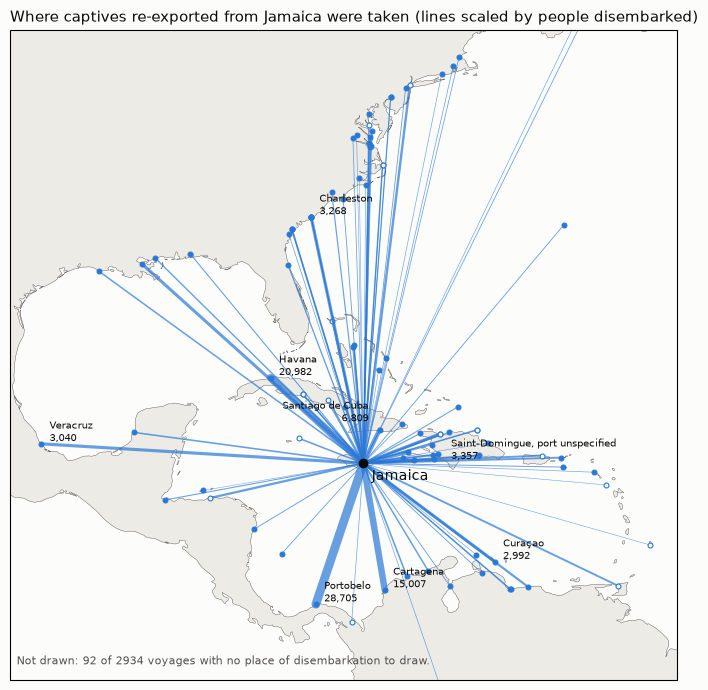

In [13]:
ends = from_jamaica.endpoints()
ends = ends[ends.voyage_id.isin(reexports.voyage_id)]
people = reexports.set_index("voyage_id").disembarked_imputed
routes = (
    ends[ends.drawable]
    .assign(people=lambda d: d.voyage_id.map(people))
    .groupby(
        [
            "disembarkation_map_code",
            "disembarkation_place_name",
            "disembarkation_lat",
            "disembarkation_lon",
            "disembarkation_precision",
        ],
        dropna=False,
    )  # fmt: skip
    .agg(voyages=("voyage_id", "size"), people=("people", "sum"))
    .reset_index()
)
not_drawn = ends[~ends.drawable]
kingston = v.sql("SELECT lat, lon FROM places WHERE name = 'Kingston'").to_pandas().iloc[0]

fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([-98, -58, 5, 44], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor=LAND, edgecolor="none")
ax.add_feature(cfeature.COASTLINE, linewidth=0.3, edgecolor=MUTED)
ax.set_facecolor(SEA)
top = routes.people.max()
for r in routes.sort_values("people").itertuples():
    ax.plot(
        [kingston.lon, r.disembarkation_lon], [kingston.lat, r.disembarkation_lat],
        transform=ccrs.PlateCarree(), color=HIGHLIGHT, alpha=0.7, solid_capstyle="round",
        linewidth=0.3 + 6 * (r.people / top) ** 0.5,
    )  # fmt: skip
    rep = r.disembarkation_precision != "place"
    ax.plot(
        r.disembarkation_lon, r.disembarkation_lat, "o", transform=ccrs.PlateCarree(),
        markersize=3.5, markerfacecolor=SURFACE if rep else HIGHLIGHT,
        markeredgecolor=HIGHLIGHT, markeredgewidth=0.8,
    )  # fmt: skip
# Label positions (points) for places that sit close together: (dx, dy, alignment).
LABELS = {
    "Santiago de Cuba": (-8, 6, "right"),
    "Saint-Domingue, port unspecified": (8, -18, "left"),
}
for r in routes.nlargest(8, "people").itertuples():
    dx, dy, ha = LABELS.get(r.disembarkation_place_name, (6, 2, "left"))
    ax.annotate(
        f"{r.disembarkation_place_name}\n{int(r.people):,}",
        (r.disembarkation_lon, r.disembarkation_lat), xytext=(dx, dy), textcoords="offset points",
        ha=ha, fontsize=7.5, transform=ccrs.PlateCarree(),
    )  # fmt: skip
ax.plot(kingston.lon, kingston.lat, "o", color=INK, markersize=6, transform=ccrs.PlateCarree())
ax.annotate("Jamaica", (kingston.lon, kingston.lat), xytext=(6, -12), textcoords="offset points",
            fontsize=10, transform=ccrs.PlateCarree())  # fmt: skip
ax.set_title(
    "Where captives re-exported from Jamaica were taken (lines scaled by people disembarked)",
    loc="left", fontsize=11,
)  # fmt: skip
ax.text(
    0.01, 0.02,
    f"Not drawn: {len(not_drawn)} of {len(ends)} voyages with no place of disembarkation to draw.",
    transform=ax.transAxes, fontsize=8, color=MUTED, va="bottom",
)  # fmt: skip
fig.tight_layout()
fig.savefig("figures/03_reexport_routes.png", dpi=150)

In [14]:
routes.nlargest(10, "people")[["disembarkation_place_name", "voyages", "people"]]

,disembarkation_place_name,voyages,people
83,Portobelo,141,28705
44,Havana,378,20982
84,Cartagena,145,15007
45,Santiago de Cuba,389,6809
75,"Saint-Domingue, port unspecified",126,3357
23,Charleston,200,3268
81,Veracruz,39,3040
50,Curaçao,112,2992
69,Jérémie,77,2977
30,New Orleans,45,2839


## Checks

The figures quoted above, checked against the tables.

In [15]:
e = everything.iloc[0]
assert (e.voyages, e.embarked, e.disembarked, e.first_year, e.last_year) == (
    3048, 133_115, 127_696, 1652, 1812,
)  # fmt: skip
assert re_summary.to_dict() == {
    "voyages": 2934, "embarked": 130_931, "disembarked": 125_967,
    "first_year": 1652, "last_year": 1812,
}  # fmt: skip
d = by_destination
assert (d.loc["Spanish mainland", "share"], d.loc["Cuba", "share"]) == (47.2, 23.8)
assert d.loc[["Within Jamaica", "Africa", "Not known"], "voyages"].tolist() == [24, 2, 88]
# The two peaks, and who they went to.
assert by_decade.total.idxmax() == 1730 and by_decade.loc[1730, "total"] == 25_725
assert by_decade.loc[1790, "Cuba"] == 16_003
assert by_decade.loc[1780, ["Saint-Domingue", "Mainland North America"]].tolist() == [6566, 5250]
assert by_decade.loc[1700:1749, "Spanish mainland"].sum() == 49_375
assert overall_share == 14.1  # about one in seven
kingston_row = ports.set_index("embarkation_place_name").loc["Kingston"]
assert (kingston_row.voyages, kingston_row.embarked) == (1367, 51_918)
r = recorded_summary.iloc[0]
assert (r.voyages, r.captives_arrived_first_landing) == (1574, 69_979)
assert len(traced) == 12
top_routes = routes.nlargest(3, "people").disembarkation_place_name.tolist()
assert top_routes == ["Portobelo", "Havana", "Cartagena"]

In [16]:
voyages.citation()

'SlaveVoyages, Trans-Atlantic Slave Trade Database, https://www.slavevoyages.org (accessed October 19, 2026).'